# MEMC exercise 6 – The rejection method

---

The inverse transform (exercise 4) needs a distribution function we can invert. What if we cannot?
The normal distribution is the typical example: $\Phi^{-1}$ has no formula and numerical inversion is
slow.

**The rejection method** generates from a density $f$ without integrating or inverting it. All it
needs is:

- to be able to **evaluate** $f(x)$ (up to a constant factor, i.e. without the normalization),
- to know a simpler density $g$ we can sample from, a multiple of which, $M g$, lies **above** $f$.

The principle: we propose a value from the simple distribution and then **reject** it with a suitable
probability, so that the accepted values have exactly the density $f$.

In this notebook you see:

- the version with a rectangle (the simplest) and a picture of why it works
- the version with an envelope, and **the normal distribution from a Cauchy envelope**
- the expected number of tries and how it affects the choice of envelope
- what happens when the constant $M$ is wrong, and how to tell

In [1]:
import math
import random
import time

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def estimate(sampler, n):
    '''Plain Monte Carlo: the average of n calls of the generator and its standard error sigma/sqrt(n).'''
    s = s2 = 0.0
    for _ in range(n):
        x = sampler()
        s += x
        s2 += x * x
    mean = s / n
    var = max(s2 / n - mean * mean, 0.0)
    return mean, math.sqrt(var / n)


def check(name, mean, se, exact, k=5):
    '''Prints the estimate and verifies it lies within k standard errors of the exact value.'''
    print(f"{name}: {mean:.5f} +- {se:.5f}  (exact {exact:.5f})")
    assert abs(mean - exact) <= k * se, name


# generators from the previous exercises
def uniform(a, b):
    return a + (b - a) * random.random()


def exponential(lam):
    return -math.log(1.0 - random.random()) / lam


def cauchy(x0=0.0, s=1.0):
    return x0 + s * math.tan(math.pi * (random.random() - 0.5))


def Phi(x):
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))

## 1. The rejection method with a rectangle

### The idea

Take any (possibly unnormalized) function $f \ge 0$ on $[a, b]$ and a rectangle
$[a, b]\times[0, C]$ such that $f(x) \le C$ everywhere. We pick points **uniformly in the rectangle**
and keep only those that lie **below the graph** of $f$. The accepted points are spread uniformly
under the graph, and so their $x$ coordinate has a density proportional to $f$.

**The algorithm:**

1. $\xi_1 \sim R(a, b)$, $\xi_2 \sim R(0, C)$ independently.
2. If $\xi_2 < f(\xi_1)$, return $\xi_1$. Otherwise throw both away and go back to step 1.

### Why it works

The probability that a proposed $\xi_1 \in dx$ is accepted is
$\dfrac{dx}{b - a}\cdot\dfrac{f(x)}{C}$, i.e. proportional to $f(x)\,dx$. So once accepted, $\xi_1$
has the density $f(x)/\int f$.

The acceptance probability is the ratio of the areas, $\dfrac{\int f}{C\,(b-a)}$, so the **expected
number of tries** per sample is $\dfrac{C\,(b-a)}{\int f}$ (for a normalized $f$ simply $C\,(b-a)$).

### What the "rectangle" actually is, as a function

The rectangle is the **constant function** $h(x) = C$ on $[a, b]$: it lies above the graph of $f$ and
we can sample from it trivially (uniformly). For a fixed $x_0$ the acceptance probability is the ratio
of two lengths:

$$P(\text{accept} \mid x_0) = \frac{f(x_0)}{C}.$$

The picture shows both quantities: on the left the geometry (the green area = we accept, the red = we
reject), on the right the acceptance probability itself as a function of $x$.

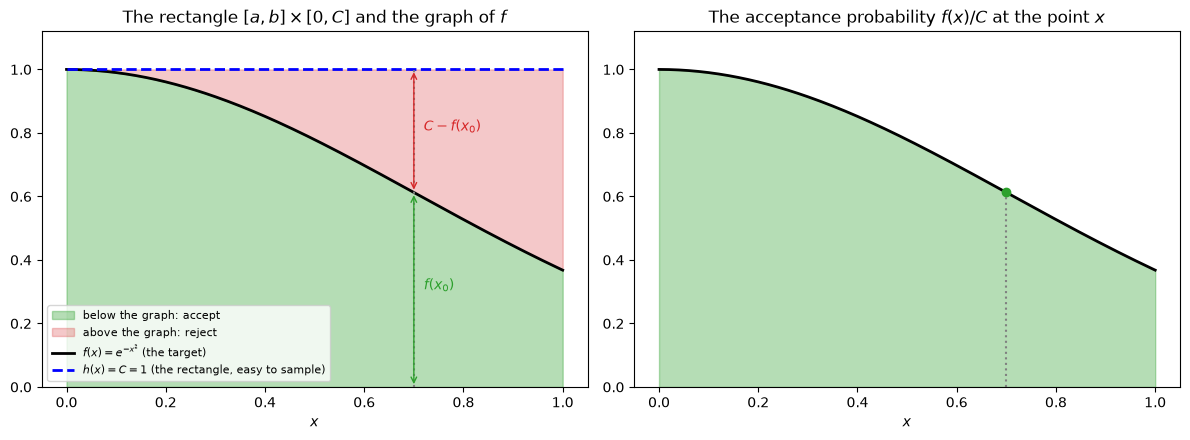

In [2]:
fb = lambda x: math.exp(-x * x)   # our f (unnormalized)
a_, b_, C_ = 0.0, 1.0, 1.0        # the rectangle [a, b] x [0, C]
grid = [i / 200 for i in range(201)]
x0 = 0.7

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
ax.fill_between(grid, [fb(x) for x in grid], color="tab:green", alpha=0.35, label="below the graph: accept")
ax.fill_between(grid, [fb(x) for x in grid], [C_] * len(grid), color="tab:red", alpha=0.25, label="above the graph: reject")
ax.plot(grid, [fb(x) for x in grid], "k", lw=2, label="$f(x) = e^{-x^2}$ (the target)")
ax.plot([a_, b_], [C_, C_], "b--", lw=2, label="$h(x) = C = 1$ (the rectangle, easy to sample)")
ax.plot([x0, x0], [0, C_], color="gray", ls=":")
ax.annotate("", xy=(x0, fb(x0)), xytext=(x0, 0), arrowprops=dict(arrowstyle="<->", color="tab:green"))
ax.annotate("", xy=(x0, C_), xytext=(x0, fb(x0)), arrowprops=dict(arrowstyle="<->", color="tab:red"))
ax.text(x0 + 0.02, fb(x0) / 2, "$f(x_0)$", color="tab:green")
ax.text(x0 + 0.02, (fb(x0) + C_) / 2, "$C - f(x_0)$", color="tab:red")
ax.set_xlabel("$x$")
ax.set_ylim(0, 1.12)
ax.set_title("The rectangle $[a,b]\\times[0,C]$ and the graph of $f$")
ax.legend(loc="lower left", fontsize=8)

axes[1].plot(grid, [fb(x) / C_ for x in grid], "k", lw=2)
axes[1].fill_between(grid, [fb(x) / C_ for x in grid], color="tab:green", alpha=0.35)
axes[1].plot([x0, x0], [0, fb(x0) / C_], color="gray", ls=":")
axes[1].scatter([x0], [fb(x0) / C_], color="tab:green", zorder=3)
axes[1].set_ylim(0, 1.12)
axes[1].set_xlabel("$x$")
axes[1].set_title("The acceptance probability $f(x)/C$ at the point $x$")
plt.tight_layout()
plt.show()

In [3]:
def rejection_box(f, C, a, b):
    '''The rejection method with the rectangle [a, b] x [0, C]. Returns (x, number of tries).'''
    tries = 0
    while True:
        tries += 1
        x = uniform(a, b)
        y = uniform(0, C)
        if y < f(x):
            return x, tries


n = 200_000

# the density f(x) = 2x on [0, 1], C = 2: E X = 2/3, expected number of tries = C (b - a) / 1 = 2
f1 = lambda x: 2 * x
check("f = 2x: E X", *estimate(lambda: rejection_box(f1, 2, 0, 1)[0], n), 2 / 3)
check("f = 2x: tries per sample", *estimate(lambda: rejection_box(f1, 2, 0, 1)[1], n), 2.0)

f = 2x: E X: 0.66690 +- 0.00053  (exact 0.66667)
f = 2x: tries per sample: 1.99983 +- 0.00316  (exact 2.00000)


### An unnormalized density

Now the function we integrated in exercise 1: $f(x) = e^{-x^2}$ on $[0, 1]$. Its integral is
$Z = \tfrac{\sqrt\pi}{2}\operatorname{erf}(1) \approx 0.7468$, so $f$ is **not normalized**, and the
rejection method does not mind. The density is $f/Z$, its expectation is
$\dfrac{1}{Z}\displaystyle\int_0^1 x e^{-x^2}\,dx = \dfrac{1 - e^{-1}}{2Z}$, and the expected number
of tries at $C = 1$ is $1/Z$.

In [4]:
f2 = lambda x: math.exp(-x * x)
Z = math.sqrt(math.pi) / 2 * math.erf(1)

check("exp(-x^2): E X", *estimate(lambda: rejection_box(f2, 1, 0, 1)[0], n), (1 - math.exp(-1)) / (2 * Z))
check("exp(-x^2): tries per sample", *estimate(lambda: rejection_box(f2, 1, 0, 1)[1], n), 1 / Z)

# the fraction of accepted points times the area of the rectangle is an estimate of the integral (hit-or-miss from exercise 1)
check("area under exp(-x^2) from the acceptance fraction", *estimate(lambda: float(uniform(0, 1) < f2(uniform(0, 1))), n), Z)

exp(-x^2): E X: 0.42258 +- 0.00061  (exact 0.42321)


exp(-x^2): tries per sample: 1.34055 +- 0.00151  (exact 1.33900)
area under exp(-x^2) from the acceptance fraction: 0.74785 +- 0.00097  (exact 0.74682)


The last line is the hit-or-miss of exercise 1: the same points, except that there we **counted**
them, and here we **keep** them.

### A picture: the simulated points and the result

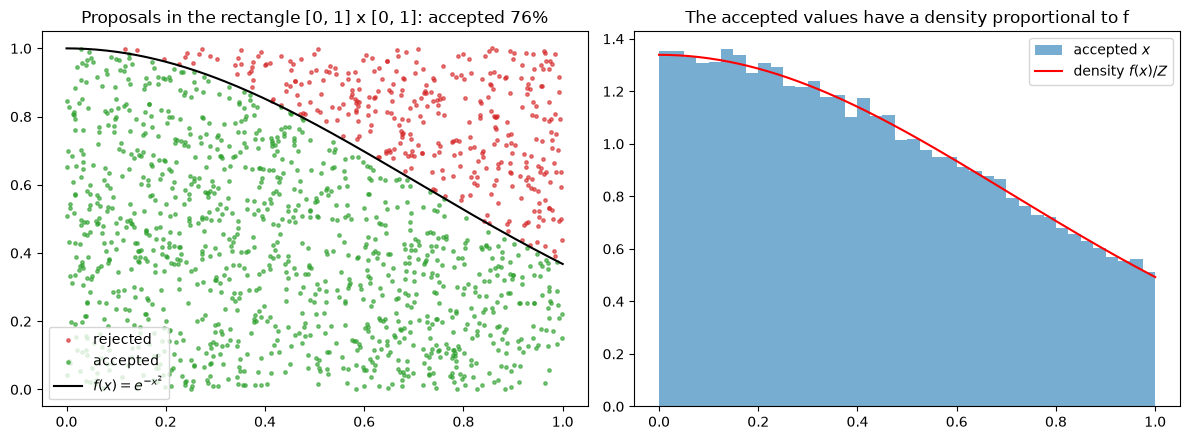

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

accepted, rejected = [], []
for _ in range(1500):
    x, y = uniform(0, 1), uniform(0, 1)
    (accepted if y < f2(x) else rejected).append((x, y))

ax = axes[0]
ax.scatter(*zip(*rejected), s=6, c="tab:red", alpha=0.6, label="rejected")
ax.scatter(*zip(*accepted), s=6, c="tab:green", alpha=0.6, label="accepted")
grid = [i / 200 for i in range(201)]
ax.plot(grid, [f2(x) for x in grid], "k", label="$f(x) = e^{-x^2}$")
ax.set_title(f"Proposals in the rectangle [0, 1] x [0, 1]: accepted {len(accepted) / 1500:.0%}")
ax.legend(loc="lower left")

xs = [rejection_box(f2, 1, 0, 1)[0] for _ in range(100_000)]
w = 1 / 40
axes[1].hist(xs, bins=40, range=(0, 1), weights=[1 / (len(xs) * w)] * len(xs), alpha=0.6, label="accepted $x$")
axes[1].plot(grid, [f2(x) / Z for x in grid], "r", label="density $f(x)/Z$")
axes[1].set_title("The accepted values have a density proportional to f")
axes[1].legend()
plt.tight_layout()
plt.show()

On the left you can see the whole principle: the green points (below the curve) stay, the red ones
are thrown away. On the right is a histogram of the accepted $x$ coordinates together with the exact
density.

## 2. An envelope instead of a rectangle

The rectangle has two weaknesses: it needs a **finite interval** and a **bounded** $f$, and if $f$ is
"spiky", most of the rectangle is empty (a lot of rejections). The generalization: instead of a
rectangle we use an **envelope** $M g(x)$, where $g$ is a density we can sample from and $M$ is a
constant such that

$$f(x) \le M\,g(x) \qquad\text{for all } x.$$

**The algorithm:**

1. $x \sim g$, $\gamma \sim R(0, 1)$ independently.
2. If $\gamma\,M\,g(x) \le f(x)$, return $x$. Otherwise go back to step 1.

(Equivalently: accept $x$ with probability $\dfrac{f(x)}{M g(x)} \le 1$.) The rectangle is a special
case: $g$ uniform on $[a, b]$, $M g = C$.

**The expected number of tries** is $M$ (when both $f$ and $g$ are normalized densities). The more
tightly the envelope fits, the closer $M$ is to one and the less we reject.

### A picture: the graph of $f$, the envelope $M g$ and the acceptance probability

The only difference from the rectangle: instead of the constant $C$, the upper bound is the curve
$M g(x)$. For a fixed $x_0$ we again have

$$P(\text{accept} \mid x_0) = \frac{f(x_0)}{M\,g(x_0)}.$$

An example: the target $f$ is the standard normal density and $g$ is the Cauchy density (we derive
the constant $M$ in the next section, here we just use it).

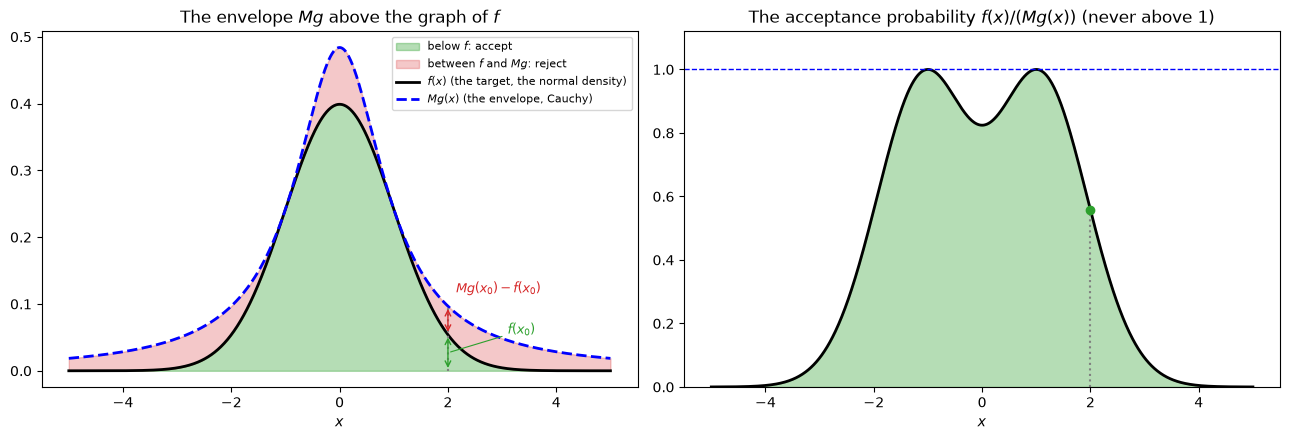

In [6]:
phi_ = lambda x: math.exp(-x * x / 2) / math.sqrt(2 * math.pi)       # the target f
gc_ = lambda x: 1.0 / (math.pi * (1 + x * x))                         # the proposal g (Cauchy)
Mc_ = math.sqrt(math.pi / 2) * 2 * math.exp(-0.5)                     # M
grid = [i / 100 - 5 for i in range(1001)]
x0 = 2.0

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.fill_between(grid, [phi_(x) for x in grid], color="tab:green", alpha=0.35, label="below $f$: accept")
ax.fill_between(grid, [phi_(x) for x in grid], [Mc_ * gc_(x) for x in grid], color="tab:red", alpha=0.25, label="between $f$ and $Mg$: reject")
ax.plot(grid, [phi_(x) for x in grid], "k", lw=2, label="$f(x)$ (the target, the normal density)")
ax.plot(grid, [Mc_ * gc_(x) for x in grid], "b--", lw=2, label="$M g(x)$ (the envelope, Cauchy)")
ax.plot([x0, x0], [0, Mc_ * gc_(x0)], color="gray", ls=":")
ax.annotate("", xy=(x0, phi_(x0)), xytext=(x0, 0), arrowprops=dict(arrowstyle="<->", color="tab:green"))
ax.annotate("", xy=(x0, Mc_ * gc_(x0)), xytext=(x0, phi_(x0)), arrowprops=dict(arrowstyle="<->", color="tab:red"))
ax.annotate("$f(x_0)$", xy=(x0, phi_(x0) / 2), xytext=(x0 + 1.1, 0.055), color="tab:green", fontsize=9,
            arrowprops=dict(arrowstyle="-", color="tab:green", lw=0.8))
ax.text(x0 + 0.15, Mc_ * gc_(x0) + 0.02, "$Mg(x_0) - f(x_0)$", color="tab:red", fontsize=9)
ax.set_xlabel("$x$")
ax.set_title("The envelope $M g$ above the graph of $f$")
ax.legend(fontsize=8)

axes[1].plot(grid, [phi_(x) / (Mc_ * gc_(x)) for x in grid], "k", lw=2)
axes[1].fill_between(grid, [phi_(x) / (Mc_ * gc_(x)) for x in grid], color="tab:green", alpha=0.35)
axes[1].plot([x0, x0], [0, phi_(x0) / (Mc_ * gc_(x0))], color="gray", ls=":")
axes[1].scatter([x0], [phi_(x0) / (Mc_ * gc_(x0))], color="tab:green", zorder=3)
axes[1].axhline(1, color="b", ls="--", lw=1)
axes[1].set_ylim(0, 1.12)
axes[1].set_xlabel("$x$")
axes[1].set_title("The acceptance probability $f(x)/(M g(x))$ (never above $1$)")
plt.tight_layout()
plt.show()

In [7]:
def rejection_envelope(f, g_pdf, g_sampler, M):
    '''The rejection method with an envelope M * g >= f. Returns (x, number of tries).'''
    tries = 0
    while True:
        tries += 1
        x = g_sampler()
        if random.random() * M * g_pdf(x) <= f(x):
            return x, tries

## 3. The normal distribution from a Cauchy envelope

The target is the standard normal density $f(x) = \dfrac{1}{\sqrt{2\pi}}e^{-x^2/2}$. For $g$ we take
the Cauchy density $g(x) = \dfrac{1}{\pi(1 + x^2)}$: we can sample from it by the inverse transform
(exercise 4) and it has **heavier tails** than $f$, so the envelope has no trouble with the infinite
interval.

The constant $M$ is the supremum of the ratio:

$$\frac{f(x)}{g(x)} = \sqrt{\frac{\pi}{2}}\,(1 + x^2)\,e^{-x^2/2}.$$

The derivative vanishes at $x = 0$ and at $x^2 = 1$; the maximum is at $x = \pm 1$, hence

$$M = \sup_x \frac{f(x)}{g(x)} = \sqrt{\frac{\pi}{2}}\cdot 2\,e^{-1/2} \approx 1.520.$$

In [8]:
f = lambda x: math.exp(-x * x / 2) / math.sqrt(2 * math.pi)
g = lambda x: 1.0 / (math.pi * (1 + x * x))
M = math.sqrt(math.pi / 2) * 2 * math.exp(-0.5)
print(f"M = {M:.4f}")


def normal_from_cauchy():
    '''The standard normal distribution by rejection with a Cauchy envelope. Returns (x, number of tries).'''
    return rejection_envelope(f, g, cauchy, M)


check("E X", *estimate(lambda: normal_from_cauchy()[0], n), 0.0)
check("E X^2", *estimate(lambda: normal_from_cauchy()[0] ** 2, n), 1.0)
check("P(X < 1)", *estimate(lambda: float(normal_from_cauchy()[0] < 1), n), Phi(1))
check("tries per sample", *estimate(lambda: normal_from_cauchy()[1], n), M)

M = 1.5203
E X: -0.00188 +- 0.00224  (exact 0.00000)
E X^2: 0.99496 +- 0.00315  (exact 1.00000)


P(X < 1): 0.84071 +- 0.00082  (exact 0.84134)
tries per sample: 1.52079 +- 0.00199  (exact 1.52035)


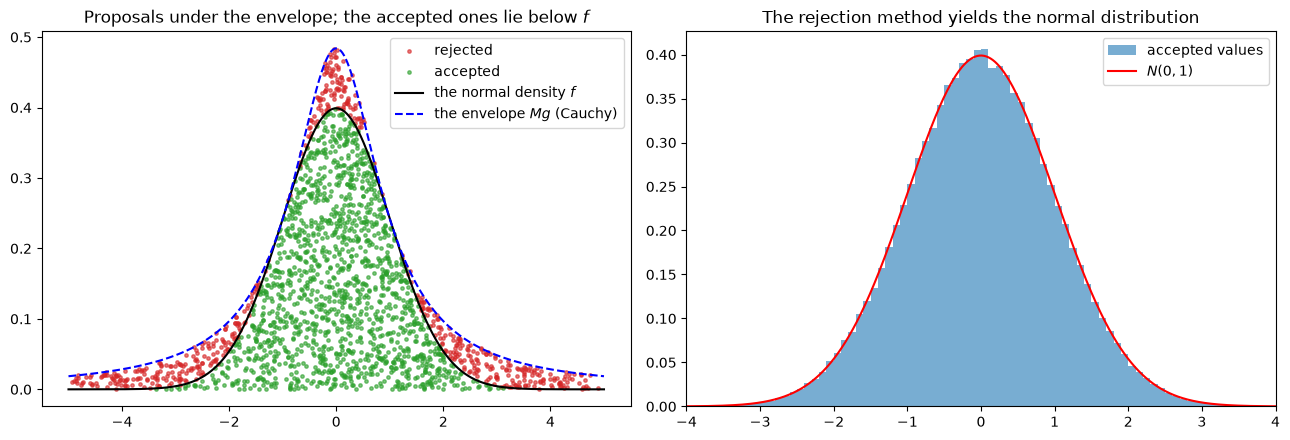

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# left: proposals x ~ Cauchy, y ~ R(0, M g(x)); we show those with |x| < 5
accepted, rejected = [], []
while len(accepted) + len(rejected) < 2000:
    x = cauchy()
    if abs(x) > 5:
        continue
    y = uniform(0, M * g(x))
    (accepted if y <= f(x) else rejected).append((x, y))

ax = axes[0]
ax.scatter(*zip(*rejected), s=6, c="tab:red", alpha=0.6, label="rejected")
ax.scatter(*zip(*accepted), s=6, c="tab:green", alpha=0.6, label="accepted")
grid = [i / 100 - 5 for i in range(1001)]
ax.plot(grid, [f(x) for x in grid], "k", label="the normal density $f$")
ax.plot(grid, [M * g(x) for x in grid], "b--", label="the envelope $M g$ (Cauchy)")
ax.set_title("Proposals under the envelope; the accepted ones lie below $f$")
ax.legend()

# right: a histogram of the accepted values
xs = [normal_from_cauchy()[0] for _ in range(200_000)]
w = 8 / 80
axes[1].hist(xs, bins=80, range=(-4, 4), weights=[1 / (len(xs) * w)] * len(xs), alpha=0.6, label="accepted values")
axes[1].plot(grid, [f(x) for x in grid], "r", label="$N(0, 1)$")
axes[1].set_xlim(-4, 4)
axes[1].set_title("The rejection method yields the normal distribution")
axes[1].legend()
plt.tight_layout()
plt.show()

The dashed blue line is the envelope $M g$: it lies above $f$ everywhere and touches it at
$x = \pm 1$ (where the ratio $f/g$ is largest). We accept only the proposals below the curve $f$. The
area under the envelope is $M \approx 1.52$ and the area under $f$ is $1$, so we accept about
$1/1.52 \approx 66\,\%$ of the proposals.

## 4. Choosing the envelope

### Finding $M$

$M$ is the supremum of $f/g$. It can be derived **analytically** (as above), or estimated crudely and
numerically on a grid:

In [10]:
def find_M(f, g, lo=-10.0, hi=10.0, steps=20_000):
    '''A crude numerical estimate of sup f/g on a grid. Deriving M analytically is more accurate and safer.'''
    return max(f(lo + (hi - lo) * i / steps) / g(lo + (hi - lo) * i / steps) for i in range(steps + 1))


print(f"Cauchy envelope:   numerically {find_M(f, g):.4f},  analytically {M:.4f}")

# the Laplace (double exponential) envelope: g(x) = e^{-|x|} / 2, the generator = a random sign * Exp(1)
g_laplace = lambda x: 0.5 * math.exp(-abs(x))
laplace = lambda: exponential(1.0) if random.random() < 0.5 else -exponential(1.0)
M_laplace = math.sqrt(2 * math.e / math.pi)
print(f"Laplace envelope:  numerically {find_M(f, g_laplace):.4f},  analytically {M_laplace:.4f}")

Cauchy envelope:   numerically 1.5203,  analytically 1.5203
Laplace envelope:  numerically 1.3155,  analytically 1.3155


The numerical estimate can be **wrong** if the maximum falls between grid points or is sharp. Use it
to verify a derived value, not in place of the derivation.

### Which envelope is better?

A smaller $M$ means fewer rejections. We compare the Cauchy and the Laplace envelope for the same
target density (and alongside them the numerical inversion by bisection from exercise 4 and the
library generator):

In [11]:
def invert_by_bisection(F, gamma, lo=-10.0, hi=10.0, iterations=60):
    for _ in range(iterations):
        mid = (lo + hi) / 2
        if F(mid) < gamma:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


generators = {
    "Cauchy envelope": lambda: rejection_envelope(f, g, cauchy, M)[0],
    "Laplace envelope": lambda: rejection_envelope(f, g_laplace, laplace, M_laplace)[0],
    "numerical inversion (exercise 4)": lambda: invert_by_bisection(Phi, random.random()),
    "random.gauss (library)": lambda: random.gauss(0, 1),
}

m_time = 50_000
print(f"{'method':34s} {'E X^2':>8s} {'time per draw':>17s}")
for name, gen in generators.items():
    t0 = time.perf_counter()
    m, se = estimate(lambda: gen() ** 2, m_time)
    t = (time.perf_counter() - t0) / m_time
    print(f"{name:34s} {m:8.4f} {t * 1e6:14.2f} us")

for name, gen, MM in (("Cauchy", cauchy, M), ("Laplace", laplace, M_laplace)):
    pg = g if name == "Cauchy" else g_laplace
    m, se = estimate(lambda: rejection_envelope(f, pg, gen, MM)[1], 100_000)
    check(f"tries per sample, {name} (M = {MM:.4f})", m, se, MM)

method                                E X^2     time per draw
Cauchy envelope                      0.9943           0.72 us
Laplace envelope                     0.9958           0.73 us


numerical inversion (exercise 4)     1.0057           9.63 us
random.gauss (library)               1.0046           0.34 us
tries per sample, Cauchy (M = 1.5203): 1.52484 +- 0.00282  (exact 1.52035)
tries per sample, Laplace (M = 1.3155): 1.31441 +- 0.00204  (exact 1.31549)


The Laplace envelope is tighter ($M \approx 1.32$ against $1.52$), so it rejects less. The rejection
method is an order of magnitude faster than the numerical inversion and only about twice as slow as
the library's `random.gauss` (which uses a different, heavily optimized algorithm). The exact factors
depend on the machine; what is robust is the ordering.

### The envelope has to be above $f$ everywhere

If $M g$ runs below $f$ anywhere, the algorithm **silently returns the wrong distribution**: in the
places where $f > M g$ we accept with probability $1$ instead of the correct, higher value, so the
density is understated there. Let us try it with a constant $M$ that is too small:

In [12]:
for M_wrong in (M, 1.2, 1.0):
    try:
        check(f"M = {M_wrong:.4f}: E X^2", *estimate(lambda: rejection_envelope(f, g, cauchy, M_wrong)[0] ** 2, 300_000), 1.0)
        m, se = estimate(lambda: rejection_envelope(f, g, cauchy, M_wrong)[1], 100_000)
        print(f"   tries per sample: {m:.4f}  (theory: M = {M_wrong:.4f})")
    except AssertionError:
        m, se = estimate(lambda: rejection_envelope(f, g, cauchy, M_wrong)[1], 100_000)
        print(f"   the test FAILED; tries per sample: {m:.4f}, which is more than M = {M_wrong:.4f}")

M = 1.5203: E X^2: 0.99669 +- 0.00257  (exact 1.00000)
   tries per sample: 1.5185  (theory: M = 1.5203)


M = 1.2000: E X^2: 1.03429 +- 0.00272  (exact 1.00000)
   the test FAILED; tries per sample: 1.3594, which is more than M = 1.2000


M = 1.0000: E X^2: 1.09763 +- 0.00287  (exact 1.00000)
   the test FAILED; tries per sample: 1.3376, which is more than M = 1.0000


With too small an $M$ the **test on $E X^2$ fails** (it comes out above $1$). There is a second
warning as well: the average number of tries **does not match** $M$ (at $M = 1.2$ it comes out around
$1.36$ instead of $1.2$). The accepted part of the envelope has an area smaller than $1$, so we need
more tries per sample than the theory says. If the measured number of tries in your implementation
does not match $M$, look for the bug in $M$.

### When no envelope exists

For $f \le Mg$ to hold with a finite $M$, the density $g$ must have **tails at least as heavy** as
$f$. Let us try the opposite problem: the target is the Cauchy density and the envelope is normal. The
ratio $f/g$ grows beyond all bounds:

In [13]:
f_cauchy = lambda x: 1.0 / (math.pi * (1 + x * x))
g_normal = lambda x: math.exp(-x * x / 2) / math.sqrt(2 * math.pi)

print(f"{'x':>3s} {'f_Cauchy(x) / g_normal(x)':>28s}")
for x in (1, 2, 3, 5, 10):
    print(f"{x:3d} {f_cauchy(x) / g_normal(x):28.4g}")

  x    f_Cauchy(x) / g_normal(x)
  1                       0.6577
  2                        1.179
  3                        7.182
  5                         8235
 10                    4.096e+19


No finite $M$ exists, so the normal distribution cannot be used as an envelope for the Cauchy one
(and in this case the inverse transform, which works without an envelope, is the right tool).

## 5. An alternative: NumPy

The rejection method can be done in **batches**: we propose a whole array of candidates, reject with
a mask and repeat until we have enough. Careful: the batch has to be larger than we need, because we
accept only $\approx 1/M$ of them.

In [14]:
try:
    import numpy as np

    rng = np.random.default_rng(1)

    def normal_numpy(N):
        '''The rejection method in batches: candidates from the Cauchy, with the mask f(x) >= γ M g(x).'''
        result = np.empty(0)
        while result.size < N:
            how_many = int((N - result.size) * M * 1.1) + 100
            x = rng.standard_cauchy(how_many)
            u = rng.random(how_many)
            fx = np.exp(-x * x / 2) / np.sqrt(2 * np.pi)
            gx = 1.0 / (np.pi * (1 + x * x))
            result = np.concatenate([result, x[u * M * gx <= fx]])
        return result[:N]

    N = 1_000_000
    t0 = time.perf_counter()
    x = normal_numpy(N)
    t_rej = time.perf_counter() - t0

    t0 = time.perf_counter()
    y = rng.standard_normal(N)
    t_lib = time.perf_counter() - t0

    print(f"rejection method: E X = {x.mean():+.4f}, E X^2 = {np.mean(x * x):.4f},  {t_rej * 1e3:.0f} ms")
    print(f"standard_normal:  E X = {y.mean():+.4f}, E X^2 = {np.mean(y * y):.4f},  {t_lib * 1e3:.0f} ms")
except ModuleNotFoundError:
    print("NumPy is not installed, run:  uv sync")

rejection method: E X = -0.0022, E X^2 = 0.9980,  58 ms
standard_normal:  E X = -0.0008, E X^2 = 0.9989,  5 ms


The rejection method in vectorized form is orders of magnitude faster than a loop in pure Python, but
the library's `standard_normal` is still faster (it uses a different algorithm, the so-called
*ziggurat*, which is a refined variant of the same idea with precomputed envelopes).

## Summary

| Concept | What to remember |
|---------|------------------|
| The rectangle version | points uniformly in $[a,b]\times[0,C]$, keep those below the graph of $f$; $f$ need not be normalized |
| The envelope version | $x \sim g$, accept if $\gamma\,M\,g(x) \le f(x)$; requires $f \le M g$ everywhere |
| Expected number of tries | $M$ (for normalized densities); the rectangle: $C(b-a)/\int f$ |
| Choosing the envelope | tight ($M$ close to $1$); $g$ must have tails at least as heavy as $f$ |
| A wrong $M$ | a silent bug: the distribution is distorted; the $E X^2$ test and a try count that does not match $M$ will reveal it |
| Normal from Cauchy | $M = \sqrt{\pi/2}\cdot 2e^{-1/2} \approx 1.52$; from the Laplace, $M = \sqrt{2e/\pi} \approx 1.32$ |
| The link to exercise 1 | hit-or-miss counts the points below the graph, the rejection method keeps them |

### Try it yourself

1. **Beta(2, 2):** the density $f(x) = 6x(1-x)$ on $[0, 1]$. Use a rectangle with the smallest
   possible $C$ (the maximum is $1.5$ at $x = 1/2$). Verify $E X = 1/2$, $D X = 1/20$ and an expected
   number of tries of $1.5$.
2. **The half-normal distribution from an exponential envelope:** the target density is
   $f(x) = \sqrt{2/\pi}\,e^{-x^2/2}$ for $x > 0$, the envelope is $g(x) = e^{-x}$. Derive
   $M = \sqrt{2e/\pi}$, implement it and verify $E X = \sqrt{2/\pi}$. Then add a **random sign** and
   you have $N(0, 1)$ with an even tighter envelope than before. How many tries does it cost?
3. In the loop, move $M$ $5\,\%$ below its correct value. Does the $E X^2$ test catch it at
   $n = 200\,000$? How many more samples do you need to notice a $2\,\%$ error in $M$?